# Ariketa 5.1 — Perceptroitik sarera: XOR zerotik 🏴 (EGITEKO)

Neurona **bakar** batek muga **lineala** baino ezin du ikasi. Gaur ikusiko dugu zergatik **ez** den nahikoa XOR-erako, eta **geruza ezkutu + aktibazio ez-lineala** duen sare bat eraikiko dugu **zerotik** (NumPy hutsa, TensorFlow gabe).

UD4ko zikloa zabaltzen dugu: **backpropagation-ek gradienteak kalkulatzen ditu kate-erregelaz**, eta **Gradient Descent-ek gradiente horiek erabiltzen ditu pisuak eguneratzeko**.


> 🌐 **5072 ML LAB · XOR PLAYGROUND**  
> XOR linealki banaezina dela eta aktibazio ez-linealak espazioa nola eraldatzen duen modu bisualean ikusteko:  
> **https://rbarrenago.github.io/5072-ml/demos/xor-playground/**


## 📝 Hiru modu

- 🟢 **KOMENTATU:** `#`-aren ondoren azaldu zer egiten duen.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** zati osoa idatzi.


## 1.1 — Neurona bat ez da nahikoa: XOR 💡 (klase parte-hartzailea)

**XOR** funtzioa: berdinak → 0, desberdinak → 1.

| x1 | x2 | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

**Ez dago zuzen bakar** bat 1ak eta 0ak banatzen dituenik. Ikus dezagun neurona batek (logistikoa) huts egiten duela.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression

X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)  #
y = np.array([[0],[1],[1],[0]], dtype=float)  #

neurona = LogisticRegression().fit(X, y.ravel())  #
print('Iragarpenak:', neurona.predict(X), '| benetakoa:', y.ravel().astype(int))  #
print('Probak:', np.round(neurona.predict_proba(X)[:,1], 2))  #
print('-> Neurona batek EZIN du XOR ebatzi (XOR ez da linealki banagarria).')


Iragarpenak: [0. 0. 0. 0.] | benetakoa: [0 1 1 0]
Probak: [0.5 0.5 0.5 0.5]
-> Neurona batek EZIN du XOR ebatzi (XOR ez da linealki banagarria).


## 1.2 — Sare bat zerotik: geruza ezkutua 🏴 (laborategia)

Arkitektura: **2 sarrera → 2 neurona ezkutu → 1 irteera**, sigmoide aktibazioarekin.

$$h = \sigma(X W_1 + b_1) \qquad \hat{y} = \sigma(h W_2 + b_2)$$

Gakoa ez da geruza ezkutua bakarrik: **geruza ezkutua + aktibazio ez-lineala** da sarrera-espazioa eraldatzeko aukera ematen duena.


In [2]:
def sigmoide(z):  #
    return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(42)  #
W1 = rng.normal(0, 1, (2, 2))  #
b1 = np.zeros((1, 2))  #
W2 = rng.normal(0, 1, (2, 1))  #
b2 = np.zeros((1, 1))  #
print('Hasierako pisuak sortuta. W1 forma:', W1.shape, '| W2 forma:', W2.shape)  #

Hasierako pisuak sortuta. W1 forma: (2, 2) | W2 forma: (2, 1)


### a) Entrenamendua: forward + backprop + update 🟡

Lau urrats:

1. **Forward:** iragarpena kalkulatu.
2. **Galera:** MSE kalkulatu.
3. **Backpropagation:** gradienteak **kate-erregelaz** kalkulatu (irteeratik atzera).
4. **Gradient Descent:** gradiente horiekin `W` eta `b` eguneratu.

> 💡 **Zergatik MSE XOR-en?** UD4rekin lotura matematikoa garbi ikusteko erabiltzen dugu. Sailkapen bitarrean, praktikan, **Binary Cross-Entropy** da aukera estandarragoa.

**Hutsuneak bete:** sigmoidearen deribatua (`a(1-a)`) backward-ean.


In [5]:
lr = 0.5
epochs = 8000
n = len(X)
historia = []
for e in range(epochs):
    # --- FORWARD ---
    z1 = X @ W1 + b1; a1 = sigmoide(z1)  # geruza ezkutua
    z2 = a1 @ W2 + b2; a2 = sigmoide(z2)  # irteera
    historia.append(np.mean((a2 - y)**2))  # MSE
    # --- BACKWARD (kate-erregela) ---
    d_a2 = 2 * (a2 - y) / n
    d_z2 = d_a2 * (a2 * (1 - a2))  # bete: sigmoidearen deribatua irteeran (a2*(1-a2))
    dW2 = a1.T @ d_z2; db2 = d_z2.sum(0, keepdims=True)
    d_a1 = d_z2 @ W2.T  # errorea atzera
    d_z1 = d_a1 * (a1 * (1 - a1))  # bete: sigmoidearen deribatua ezkutuan (a1*(1-a1))
    dW1 = X.T @ d_z1; db1 = d_z1.sum(0, keepdims=True)
    # --- EGUNERATU ---
    W2 -= lr * dW2; b2 -= lr * db2; W1 -= lr * dW1; b1 -= lr * db1
print('MSE hasieran:', round(historia[0], 3), '-> amaieran:', round(historia[-1], 4))

MSE hasieran: 0.38 -> amaieran: 0.0017


### b) Galera-kurba 🟢


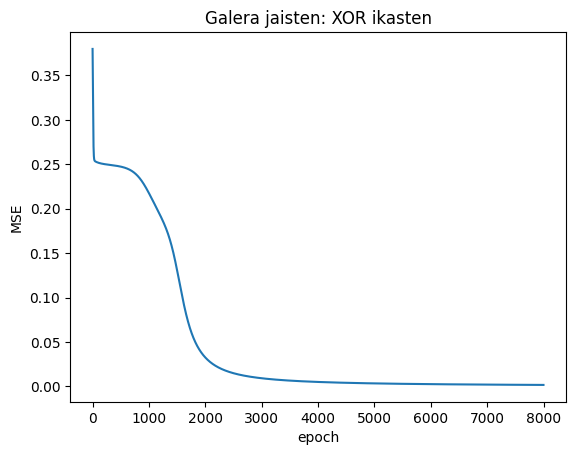

In [6]:
plt.plot(historia)  #
plt.xlabel('epoch'); plt.ylabel('MSE'); plt.title('Galera jaisten: XOR ikasten')  #
plt.show()  #

### c) Ebatzi al du XOR? 🟢


In [7]:
def iragarri(Xb):  #
    a1 = sigmoide(Xb @ W1 + b1)
    return sigmoide(a1 @ W2 + b2)

pred = iragarri(X)  #
for i in range(4):  #
    print(f'{X[i].astype(int)} -> {pred[i,0]:.2f}  (benetakoa: {int(y[i,0])})')  #
print('-> XOR EBATZITA! Neurona batek ezin zuena, SAREAK bai.')

[0 0] -> 0.04  (benetakoa: 0)
[0 1] -> 0.96  (benetakoa: 1)
[1 0] -> 0.96  (benetakoa: 1)
[1 1] -> 0.04  (benetakoa: 0)
-> XOR EBATZITA! Neurona batek ezin zuena, SAREAK bai.


### d) Erabaki-muga ikusi 🟢

Geruza ezkutuak sortzen duen muga **ez-lineala**.


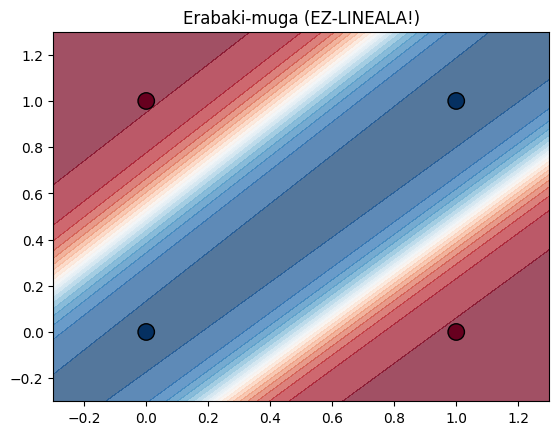

In [8]:
xx, yy = np.meshgrid(np.linspace(-0.3, 1.3, 200), np.linspace(-0.3, 1.3, 200))  #
zz = iragarri(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  #
plt.contourf(xx, yy, zz, levels=20, cmap='RdBu_r', alpha=0.7)  #
plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap='RdBu_r', edgecolors='k', s=140)  #
plt.title('Erabaki-muga (EZ-LINEALA!)'); plt.show()  #

### e) Zer ikasi du geruza ezkutuak? 🟢

Sarrerako lau puntu originalak ez dira zuzen batekin bereizgarriak. Ikus dezagun **geruza ezkutuaren aktibazioek** (`a1`) lau kasuak beste espazio batera nola eramaten dituzten.


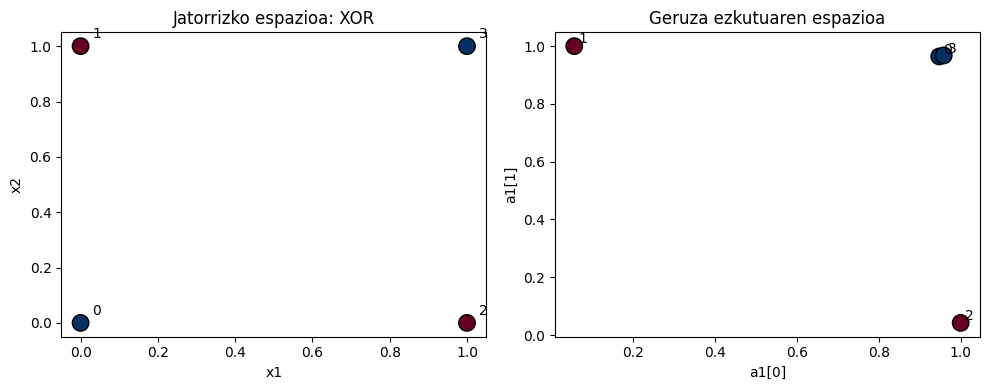

Ezkutuko aktibazioak:
[[0.947 0.964]
 [0.055 1.   ]
 [1.    0.042]
 [0.958 0.968]]


In [9]:
# Lau XOR puntuak geruza ezkutuaren espazioan
hidden = sigmoide(X @ W1 + b1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X[:,0], X[:,1], c=y.ravel(), cmap='RdBu_r', edgecolors='k', s=140)
for i, p in enumerate(X):
    axes[0].annotate(str(i), (p[0]+0.03, p[1]+0.03))
axes[0].set_title('Jatorrizko espazioa: XOR')
axes[0].set_xlabel('x1'); axes[0].set_ylabel('x2')

axes[1].scatter(hidden[:,0], hidden[:,1], c=y.ravel(), cmap='RdBu_r', edgecolors='k', s=140)
for i, p in enumerate(hidden):
    axes[1].annotate(str(i), (p[0]+0.01, p[1]+0.01))
axes[1].set_title('Geruza ezkutuaren espazioa')
axes[1].set_xlabel('a1[0]'); axes[1].set_ylabel('a1[1]')
plt.tight_layout(); plt.show()

print('Ezkutuko aktibazioak:')
print(np.round(hidden, 3))


## 🧠 Gako-mezua

- **Geruza ezkutua + aktibazio ez-lineala** → sarrera-espazioa eraldatu → XOR bezalako erlazio ez-lineala ikasi.
- **Backpropagation** → kate-erregelaz gradienteak kalkulatzen ditu.
- **Gradient Descent** → gradiente horiek erabiliz pisuak eguneratzen ditu.
- Geruza gehiago gehitzeak sarea **sakonagoa** egiten du; baina sakontasunak ez du ez-linealtasuna sortzen aktibaziorik gabe.

**Hurrengoan (S2):** kontzeptu berak Keras-en — automatizatu bai, baina kutxa beltz bihurtu gabe.


## Ondorioak

- Neurona bakarrak XOR ezin du ebatzi, **XOR ez delako linealki banagarria**.
- Sareak: **forward → loss → backprop (gradienteak) → optimizer/update**.
- Ez-linealtasuna **aktibazio-funtzioak** sartzen du.
- MSE hemen lotura didaktikoagatik erabili dugu; Keras-en sailkapen bitarrerako **Binary Cross-Entropy** erabiliko dugu.
- **Prest S2rako:** orain Keras-ek kalkulu horiek automatizatuko ditu.
